# Graphite Benchmarks – Big Experiments

## Libraries

In [1]:
from fabric import ThreadingGroup, Connection
from chi import server, ssh
import os
import warnings
import time
import sys
sys.path.append('../scripts')
from utilities import *
warnings.filterwarnings('ignore')

## Configurations

In [2]:
sshUser = "ubuntu"
server_ips = ["64.131.114.155"]
server_local_ips = {}
client_ips = ["64.131.114.143", "64.131.114.145", "64.131.114.146", "64.131.114.147",
              "64.131.114.148", "64.131.114.152", "64.131.114.153", "64.131.114.154"]

storageType = {"HDD": "/HDD", "NVME": "/NVME_RAID-0"}
SERVER_WORKING_DIR = storageType["NVME"]

## Initialize environment

In [3]:
# These groups are for processing in parallel 
serverConnections = [makeConnection(i, user=sshUser) for i in server_ips]
clientConnections = [makeConnection(i, user=sshUser) for i in client_ips]
allConnections = (serverConnections + clientConnections)
serverGroup = ThreadingGroup.from_connections(serverConnections)
clientGroup = ThreadingGroup.from_connections(clientConnections)
allGroup = ThreadingGroup.from_connections(allConnections)

# Get local IP for server
local_ips = serverGroup.run("hostname -I | cut -d ' ' -f 1", hide=True)
for i in local_ips:
    server_local_ips[i.host] = local_ips[i].stdout.strip()

# Update & Upgrade latest packages
allGroup.run("sudo apt update && sudo apt upgrade -y", hide=True)
allGroup.run("sudo reboot", disown=True)
allGroup.close()

Wait for all server to come online after reboot

In [4]:
# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Datasets

Preparing test datasets on client nodes

In [5]:
clientGroup.put("../scripts/initData.sh")
clientGroup.run("bash initData.sh MYSTIC@IIT", hide=True)

## Benchmark server (Graphite – Go-Carbon)

Prepare benchmark server

In [6]:
serverGroup.put("../scripts/Graphite/initGraphiteServer.sh")
serverGroup.put("../scripts/Graphite/go-carbon.conf")
serverGroup.put("../scripts/Graphite/carbon-api.yaml")
serverGroup.put("../scripts/Graphite/graphiteWeb.yaml")
serverGroup.put("../scripts/Graphite/storage-schemas.conf")
serverGroup.run(f"sudo chmod -R 777 {SERVER_WORKING_DIR}; bash initGraphiteServer.sh {SERVER_WORKING_DIR}", hide=True)

## Benchmark client (XBench)
Prepare benchmark client

In [7]:
clientGroup.put("../scripts/initXBenchClient.sh")
clientGroup.run("bash initXBenchClient.sh", hide=True)
clientGroup.close()

## Experiments - Settings

In [8]:
targetClients = [1, 2, 4, 8, 16, 32, 64]

## Experiment – UNARY INSERT (SEQ)
**Perform experiments**

In [9]:
runWorkload("INSERT_UNARY_SEQ", targetClients, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776565666
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776565553 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776565895
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776565781 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776566125
[Benchmark: 4] 

**Visualization**

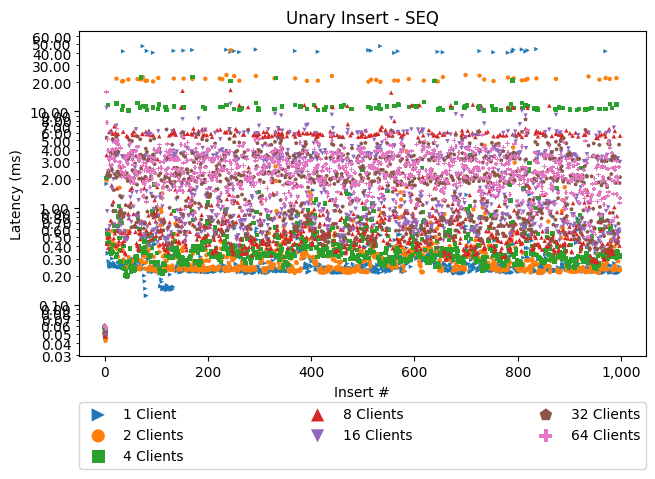

In [10]:
unaryPlots("INSERT_UNARY_SEQ", "Graphite", [1, 2, 4, 8], client_ips, "Insert", logScale=True)

## Experiment – UNARY INSERT (RAND)
**Perform experiments**

In [11]:
runWorkload("INSERT_UNARY_RAND", targetClients, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776567803
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776567689 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776568033
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776567919 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776568265
[Benchmark: 4] 

**Visualization**

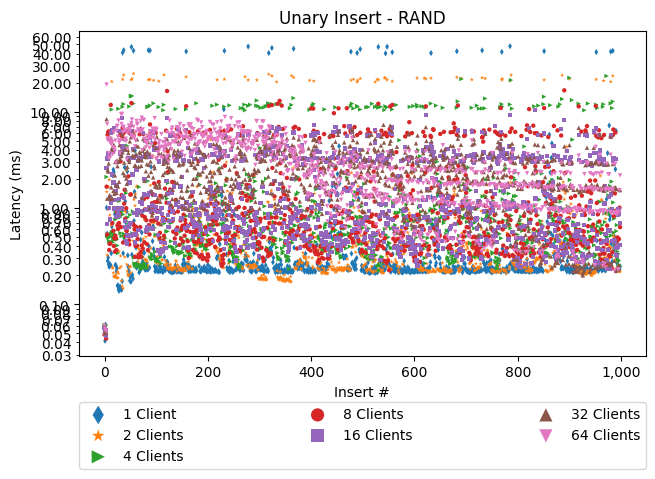

In [12]:
unaryPlots("INSERT_UNARY_RAND", "Graphite", [1, 2, 4, 8], client_ips, "Insert", logScale=True)

## Experiment – BATCH INSERT (SEQ)
**Perform experiments**

In [13]:
runWorkload("INSERT_BATCH_SEQ", targetClients, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776569992
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776569879 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776570222
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776570109 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776570462
[Benchmark: 4] 

**Visualization**

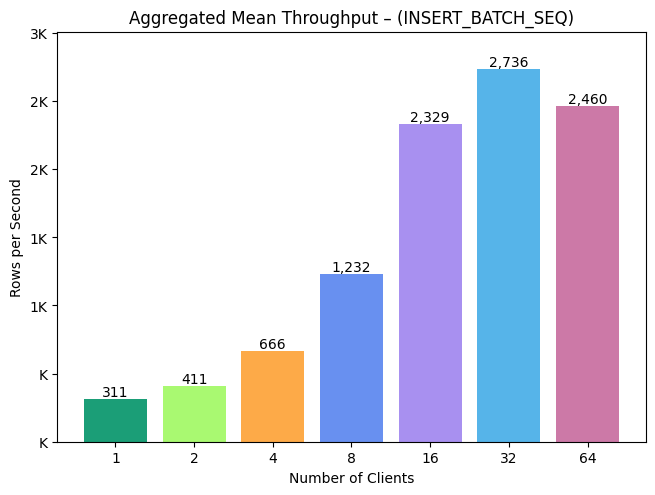

In [14]:
batchPlots("INSERT_BATCH_SEQ", "Graphite", [1, 2, 4, 8], client_ips)

## Experiment – BATCH INSERT (RAND)
**Perform experiments**

In [15]:
runWorkload("INSERT_BATCH_RAND", targetClients, server_local_ips[server_ips[0]], 2003, "Graphite", client_ips, 1000, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776572522
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776572409 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776572757
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776572644 | Delta: 113
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776572997
[Benchmark: 4] 

**Visualization**

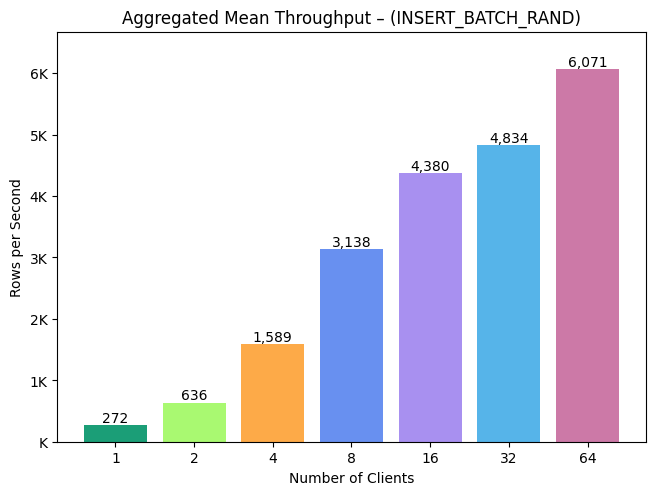

In [16]:
batchPlots("INSERT_BATCH_RAND", "Graphite", [1, 2, 4, 8], client_ips)

## Bootstrap Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [17]:
allGroup.run("sudo reboot", disown=True)
allGroup.close()

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

<div class="alert alert-block alert-info">Note: This is required so that there's actual data for clients to query from</div>

In [18]:
serverGroup.put("../scripts/restoreDB.sh")

# Restore DB
serverGroup.run(f"bash restoreDB.sh MYSTIC@IIT Graphite BENCH_DB {SERVER_WORKING_DIR}", hide=True)

# Keep checking if job is done running in tmux window
checkTmuxJobIsDone(serverGroup)

## Experiment – UNARY QUERY (SEQ)

**Perform experiments**

In [19]:
runWorkload("QUERY_UNARY_SEQ", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776583463
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776583349 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776583693
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776583579 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776583922
[Benchmark: 4] 

**Visualization**

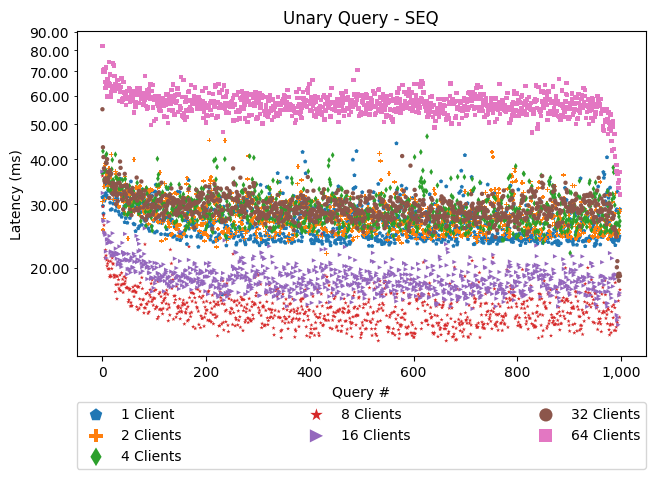

In [20]:
unaryPlots("QUERY_UNARY_SEQ", "Graphite", [1, 2, 4, 8], client_ips, "Query", logScale=True)

## Experiment – UNARY QUERY (RAND)

**Perform experiments**

In [21]:
runWorkload("QUERY_UNARY_RAND", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 1000, 0, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776585608
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776585494 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776585838
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776585724 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776586069
[Benchmark: 4] 

**Visualization**

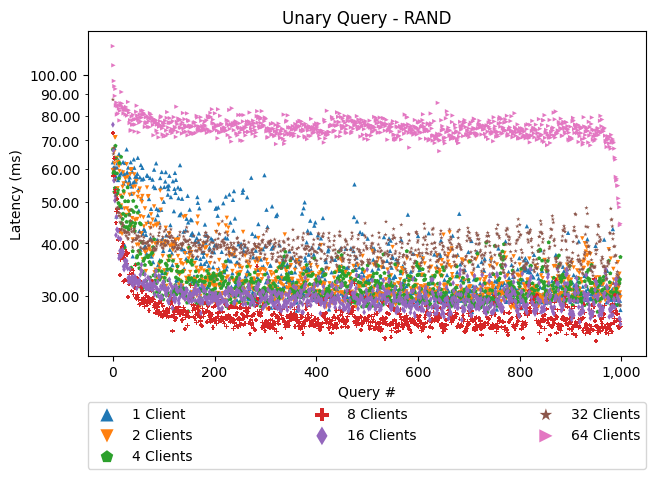

In [22]:
unaryPlots("QUERY_UNARY_RAND", "Graphite", [1, 2, 4, 8], client_ips, "Query", logScale=True)

## Experiment – BATCH QUERY (SEQ)

**Perform experiments**

In [23]:
runWorkload("QUERY_BATCH_SEQ", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 100, 10, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776587796
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776587682 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776588025
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776587911 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776588255
[Benchmark: 4] 

**Visualization**

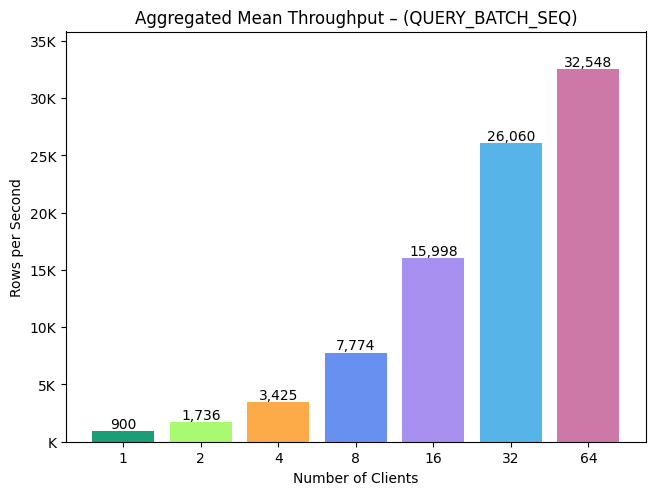

In [24]:
batchPlots("QUERY_BATCH_SEQ", "Graphite", [1, 2, 4, 8], client_ips, 100)

## Refresh Database

Reboot server to a fresh state to avoid becoming non-accessible from public network

In [25]:
allGroup.run("sudo reboot", disown=True)
allGroup.close()

# Buffer of reboot (no more +1 min shutdown-schedule delay)
time.sleep(240)

for ip in (server_ips + client_ips):
    server.wait_for_tcp(ip, 22, timeout=1200)

## Experiment – MIN AGG QUERY

**Perform experiments**

In [26]:
runWorkload("AGG_MIN_QUERY", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776590225
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776590111 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776590455
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776590340 | Delta: 115
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776590685
[Benchmark: 4] 

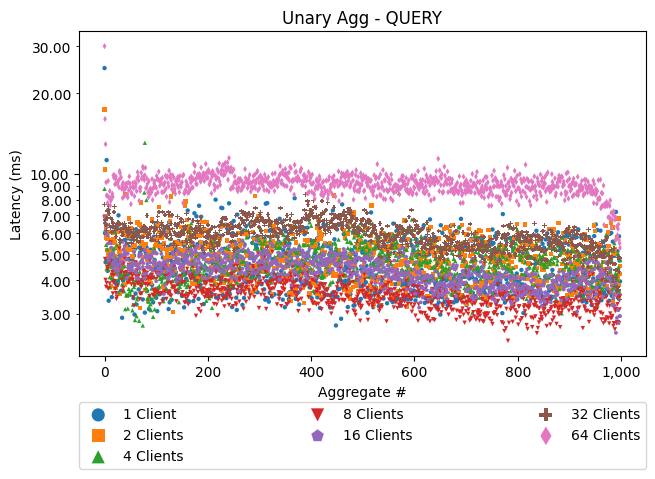

In [27]:
unaryPlots("AGG_MIN_QUERY", "Graphite", [1, 2, 4, 8], client_ips, "Aggregate", logScale=True)

## Experiment – MAX AGG QUERY

**Perform experiments**

In [28]:
runWorkload("AGG_MAX_QUERY", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776592362
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776592249 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776592591
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776592477 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776592821
[Benchmark: 4] 

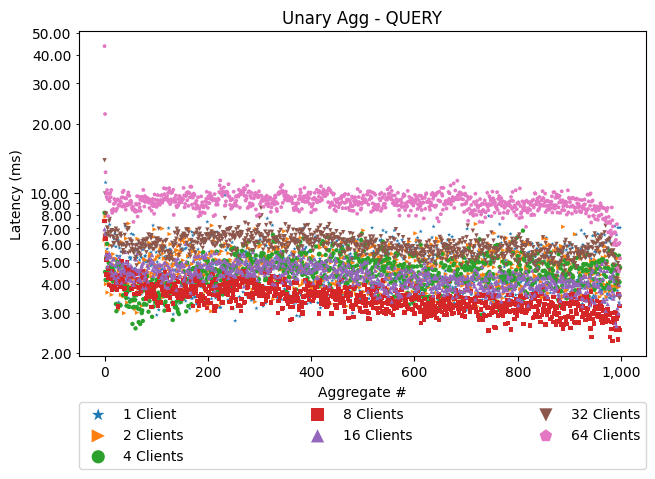

In [29]:
unaryPlots("AGG_MAX_QUERY", "Graphite", [1, 2, 4, 8], client_ips, "Aggregate", logScale=True)

## Experiment – SUM AGG QUERY

**Perform experiments**

In [30]:
runWorkload("AGG_SUM_QUERY", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776594496
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776594382 | Delta: 114
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776594726
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776594611 | Delta: 115
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776594956
[Benchmark: 4] 

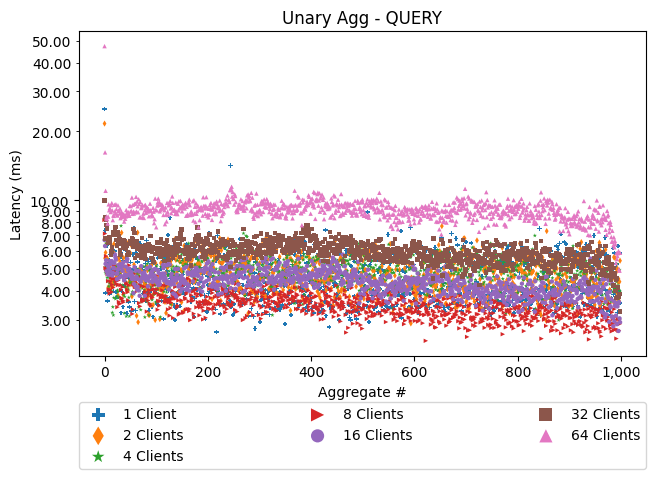

In [31]:
unaryPlots("AGG_SUM_QUERY", "Graphite", [1, 2, 4, 8], client_ips, "Aggregate", logScale=True)

## Experiment – AVG AGG QUERY

**Perform experiments**

In [32]:
runWorkload("AGG_AVG_QUERY", targetClients, server_local_ips[server_ips[0]], 8081, "Graphite", client_ips, 60, 1000, serverGroup, SERVER_WORKING_DIR, "ubuntu")

[Benchmark Config]
  Target Clients     : 1
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 1
  Total Clients Actual : 1
[Benchmark: 1] - Schedule workload on 1776596633
[Benchmark: 1] [Client: 64.131.114.143] - Time now: 1776596520 | Delta: 113
[Benchmark: 1] [Client: 64.131.114.143] - Downloaded 1 result files
[Benchmark: 1] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 2
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 2
  Total Clients Actual : 2
[Benchmark: 2] - Schedule workload on 1776596862
[Benchmark: 2] [Client: 64.131.114.143] - Time now: 1776596748 | Delta: 114
[Benchmark: 2] [Client: 64.131.114.143] - Downloaded 2 result files
[Benchmark: 2] [Server] - Downloaded system stats files
[Benchmark Config]
  Target Clients     : 4
  Total Machines     : 8
  Machines Used      : 1
  Threads per Machine: 4
  Total Clients Actual : 4
[Benchmark: 4] - Schedule workload on 1776597092
[Benchmark: 4] 

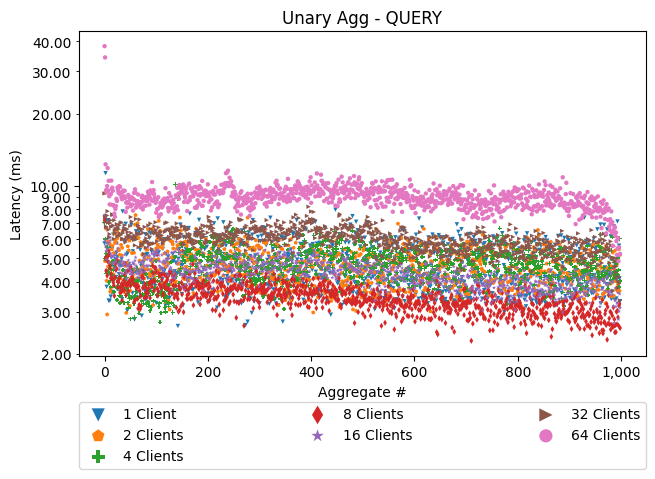

In [33]:
unaryPlots("AGG_AVG_QUERY", "Graphite", [1, 2, 4, 8], client_ips, "Aggregate", logScale=True)